<a href="https://colab.research.google.com/github/LexieLyu37/also-cracker/blob/main/02_ML_LR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CID: 02392139
Username: kl3323

In [289]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

In [290]:
# Load the diabetes dataset
diabetes = load_diabetes()

# Print data description
print(diabetes['DESCR'])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [291]:
# print feature names used in the data
diabetes.feature_names

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

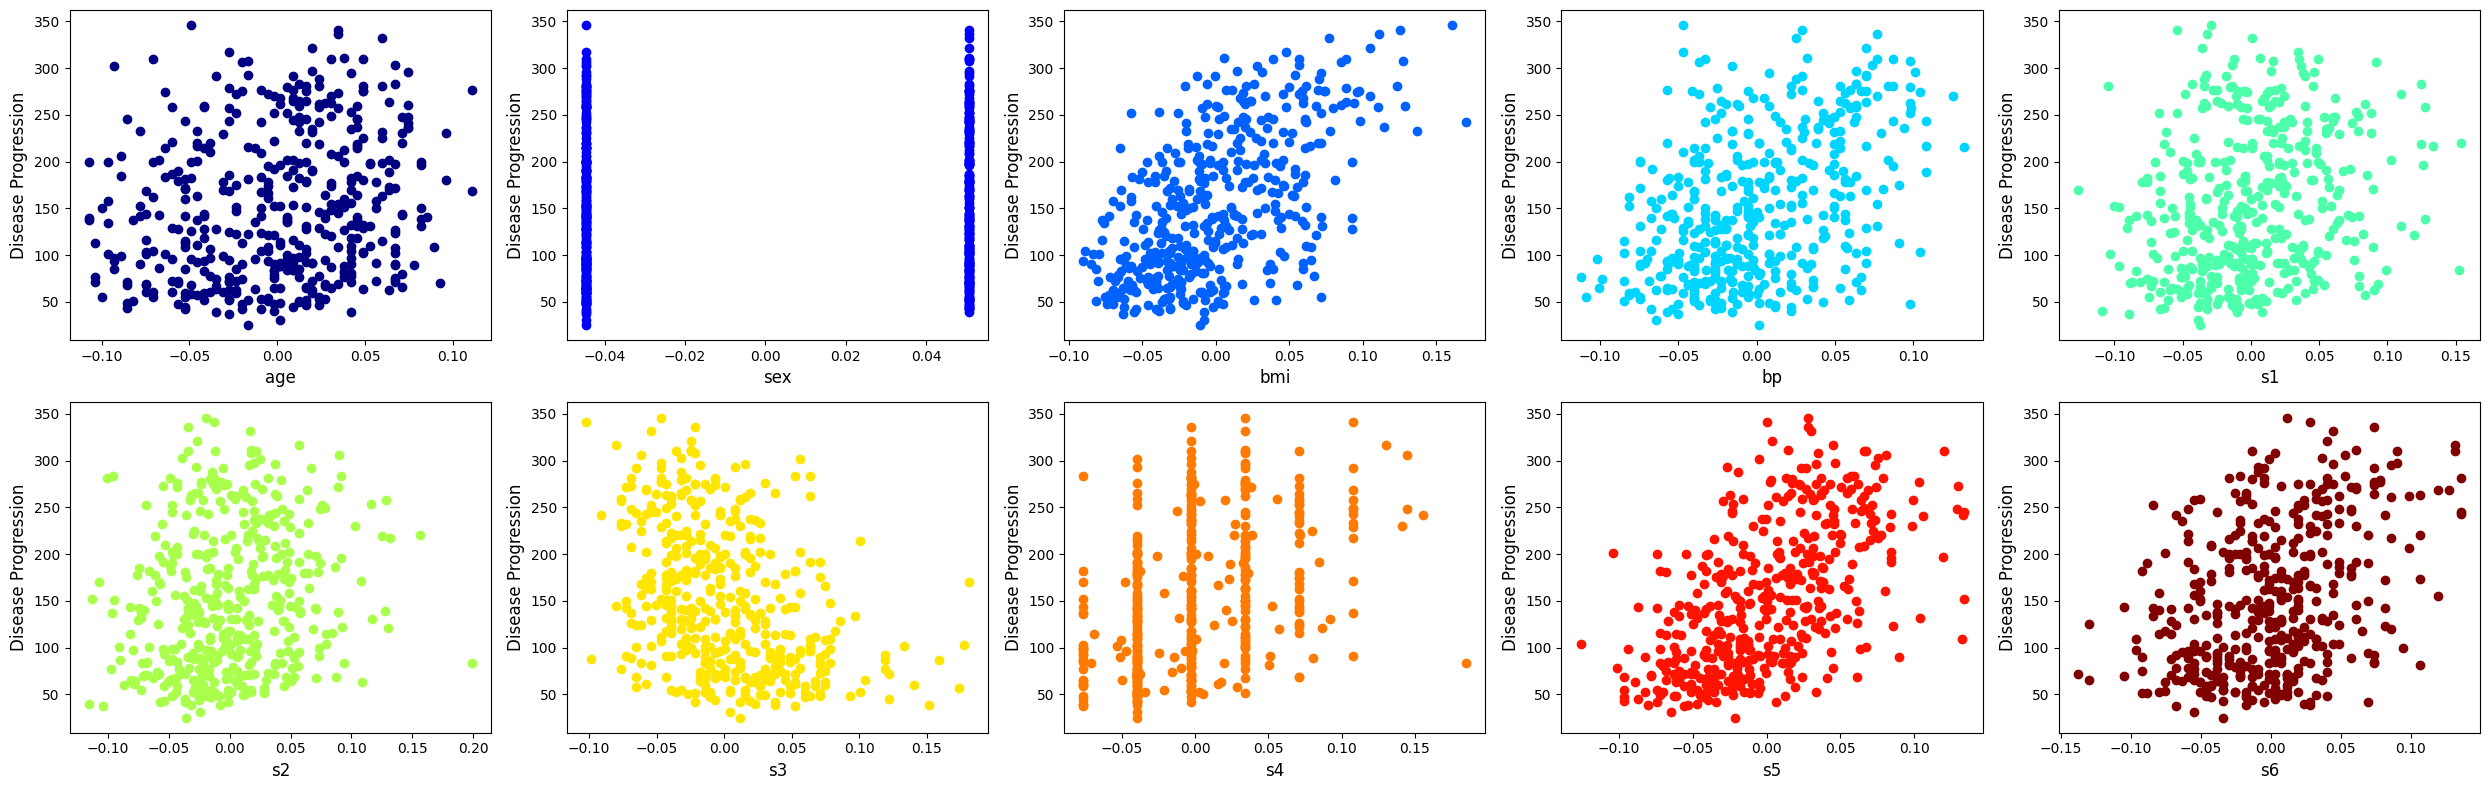

In [292]:
# Create a DataFrame to store the data and target
diabetes_data = pd.DataFrame(data=diabetes['data'], columns=diabetes['feature_names'])
diabetes_data["DP"] = diabetes['target']

# Set the size of each individual plot
plot_width = 5
plot_height = 4

# Calculate the number of rows and columns for the grid layout
num_features = len(diabetes.feature_names)
num_cols = 5
num_rows = (num_features + num_cols - 1) // num_cols

# Create subplots in a grid layout
fig, axes = plt.subplots(nrows=num_rows, ncols=num_cols, figsize=(plot_width * num_cols, plot_height * num_rows))

# Flatten the axes array to iterate over all the subplots
axes = axes.flatten()

# Define a colormap for assigning different colors to each feature plot
colors = plt.cm.jet(np.linspace(0, 1, num_features))

# Plot each feature against the target variable in separate subplots
for index, feature_name in enumerate(diabetes.feature_names):
    axes[index].scatter(diabetes.data[:, index], diabetes.target, color=colors[index])
    axes[index].set_ylabel('Disease Progression', size=12)
    axes[index].set_xlabel(feature_name, size=12)

# Hide any remaining empty subplots
for i in range(num_features, num_rows * num_cols):
    fig.delaxes(axes[i])

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

In [293]:
# function to perform the prediction by multiplying the inputs with weights
def predict_dp(X,W):
    return np.dot(X,W)

In [294]:
# function to calculate the cost (here we use MSE)
def cost(X,W,Y):
    prediction = predict_dp(X,W)
    return ((Y - prediction)**2).mean()

In [295]:
# function to plot the predicted line vs real data
def plot_line(X,W,Y):
    """Plot a line from slope and intercept"""
    y_vals = predict_dp(X,W)
    plt.figure(figsize=(5, 4))
    plt.xlabel('Age')
    plt.ylabel('Disease Progression (DP)')
    plt.scatter(X[:,1],Y, color='red', label='Actual')
    plt.plot(X[:,1], y_vals, color='black', label='Predicted')
    plt.legend(loc='upper left')
    plt.show()

In [296]:
# function to plot cost variations as the algorithm iterate
def plot_cost(cost):
    plt.figure(figsize=(5, 4))
    plt.plot(range(1, len(cost) + 1), cost)
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    plt.show()

In [297]:
# function that applies GD and fit the algorithm
def fit(n_iter,X,Y,lr):
    W0 = []
    W1 = []
    costs = []
    # Incorporate the bias term
    X = np.column_stack((np.ones(len(X)),X))
    #N = len(diabetes['target'])
    W = np.zeros(2)
    c = 0
    for i in range(n_iter):
        pred = predict_dp(X,W)
        W[0] += lr *(Y - pred).mean()
        W[1] += lr *((Y - pred)* X[:,1]).mean()
        W = np.array([W[0],W[1]])
        J = cost(X,W,Y)
        W0.append(W[0])
        W1.append(W[1])
        costs.append(J)
        c = i + 1
        if i%1000==0:
            print(f"Iteration: {i}, Cost = {J}, Weights = {W}")
            plot_line(X,W,Y)
    print(f"Iteration: {c}, Cost = {J}, Weights = {W}")
    plot_line(X,W,Y)
    plot_cost(costs)

Iteration: 0, Cost = 6160.479227680582, Weights = [136.92013575   0.6193773 ]


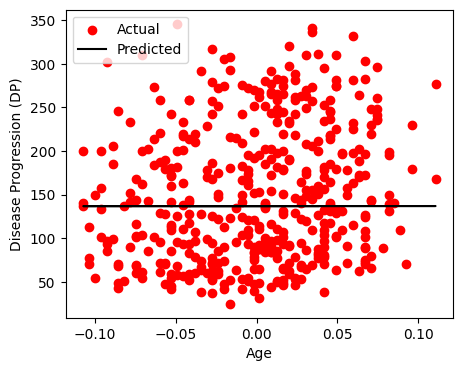

Iteration: 1000, Cost = 5724.084173552051, Weights = [152.13348416 264.64292904]


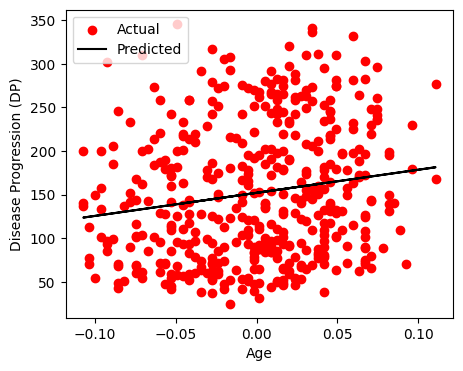

Iteration: 2000, Cost = 5720.6070282403925, Weights = [152.13348416 299.03284372]


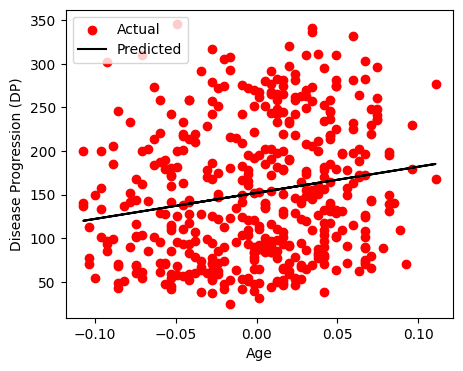

Iteration: 3000, Cost = 5720.548035346757, Weights = [152.13348416 303.51224044]


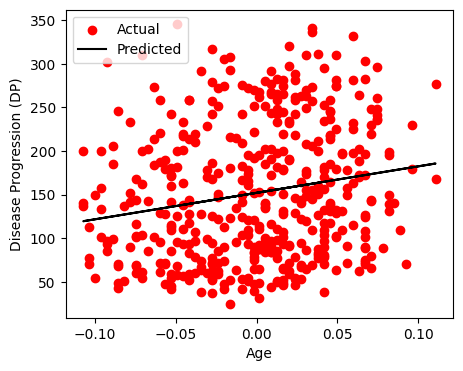

Iteration: 4000, Cost = 5720.547034479326, Weights = [152.13348416 304.09569624]


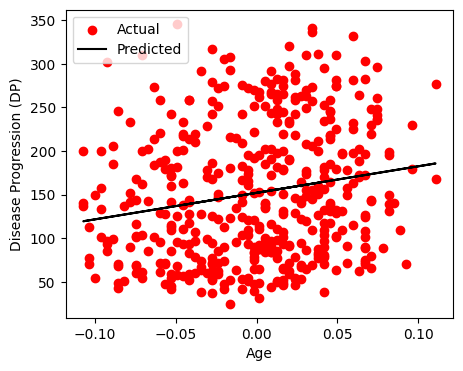

Iteration: 5000, Cost = 5720.547017498711, Weights = [152.13348416 304.17169323]


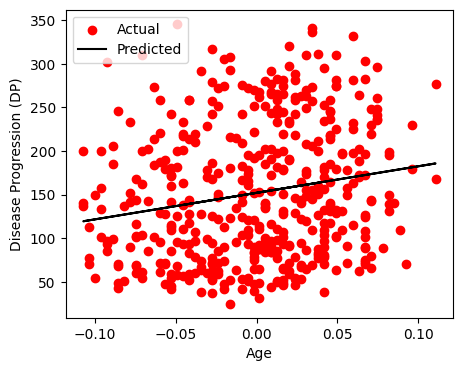

Iteration: 6000, Cost = 5720.54701721062, Weights = [152.13348416 304.18159208]


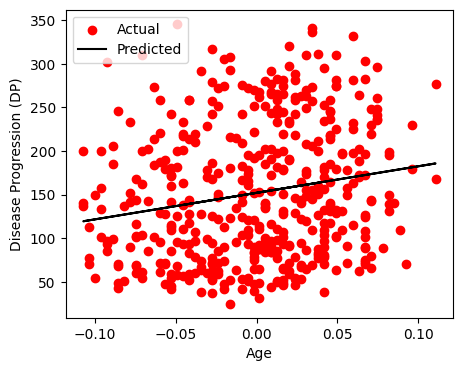

Iteration: 7000, Cost = 5720.547017205731, Weights = [152.13348416 304.18288143]


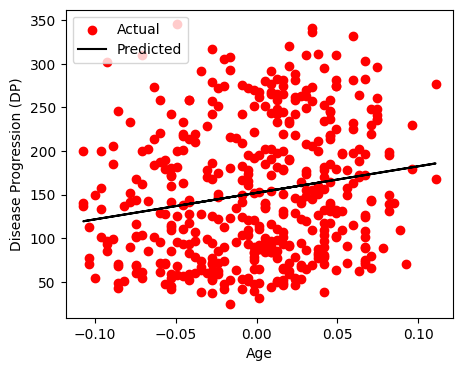

Iteration: 8000, Cost = 5720.547017205648, Weights = [152.13348416 304.18304938]


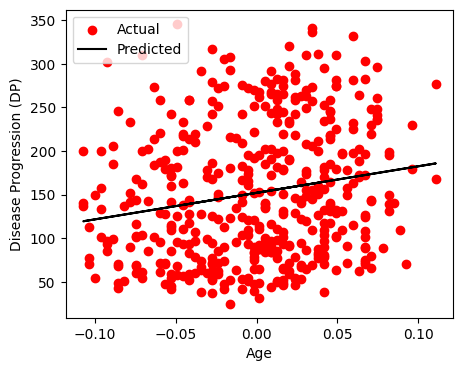

Iteration: 9000, Cost = 5720.5470172056475, Weights = [152.13348416 304.18307125]


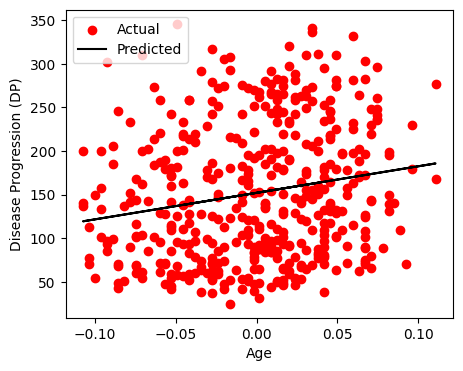

Iteration: 10000, Cost = 5720.547017205647, Weights = [152.13348416 304.1830741 ]


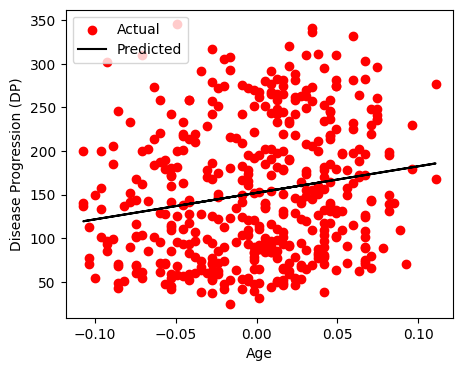

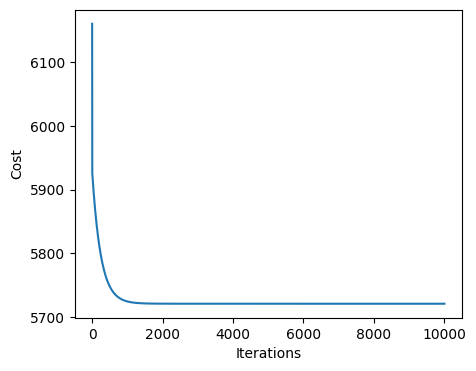

In [298]:
lr = 0.9
n_iter=10000
X = diabetes_data["age"]
Y = diabetes_data["DP"]
fit(n_iter,X,Y,lr)

[BMI] Final Weights = [152.13348416 949.43525905], Final MSE = 3890.456585461273


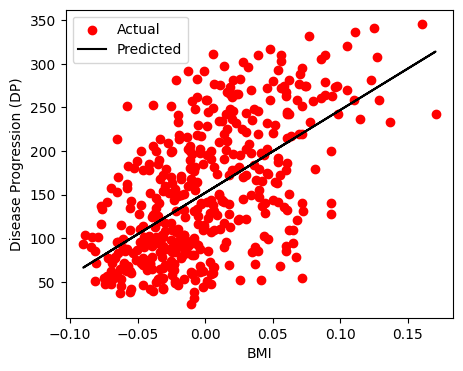

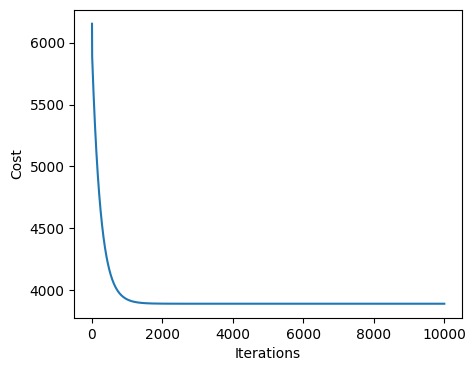

In [299]:
# Task 1
def fit_gd(n_iter, X, Y, lr, feature_name):
    """Same logic as the original fit() function, but it RETURNS
    the final weights and MSE so we can use them later in a table."""
    X = np.column_stack((np.ones(len(X)), X))
    W = np.zeros(2)
    costs = []
    for i in range(n_iter):
        pred = predict_dp(X, W)
        W[0] += lr * (Y - pred).mean()
        W[1] += lr * ((Y - pred) * X[:, 1]).mean()
        J = cost(X, W, Y)
        costs.append(J)

    print(f"[{feature_name}] Final Weights = {W}, Final MSE = {J}")

    plt.figure(figsize=(5, 4))
    plt.scatter(X[:, 1], Y, color='red', label='Actual')
    plt.plot(X[:, 1], predict_dp(X, W), color='black', label='Predicted')
    plt.xlabel(feature_name)
    plt.ylabel('Disease Progression (DP)')
    plt.legend(loc='upper left')
    plt.show()

    plot_cost(costs)
    return W, J

lr = 0.9
n_iter = 10000
Y = diabetes_data["DP"]

X_bmi = diabetes_data["bmi"]
W_bmi_gd, mse_bmi_gd = fit_gd(n_iter, X_bmi, Y, lr, "BMI")




In [300]:
# Task 1 (continued)



In [301]:
# Task 2
def closed_form(X, Y):
    """Normal Equation: w = (X^T X)^-1 X^T y, using pinv for stability."""
    X = np.column_stack((np.ones(len(X)), X))
    W = np.linalg.pinv(X.T @ X) @ X.T @ Y
    J = cost(X, W, Y)
    return W, J

In [302]:
# Task 2 (continued)
W_bmi_cf, mse_bmi_cf = closed_form(X_bmi, Y)
print(f"[BMI, Closed-form] Weights = {W_bmi_cf}, MSE = {mse_bmi_cf}")

W_bp_cf, mse_bp_cf = closed_form(X_bp, Y)
print(f"[BP, Closed-form] Weights = {W_bp_cf}, MSE = {mse_bp_cf}")

[BMI, Closed-form] Weights = [152.13348416 949.43526038], MSE = 3890.4565854612724
[BP, Closed-form] Weights = [152.13348416 714.7382595 ], MSE = 4774.113902368687


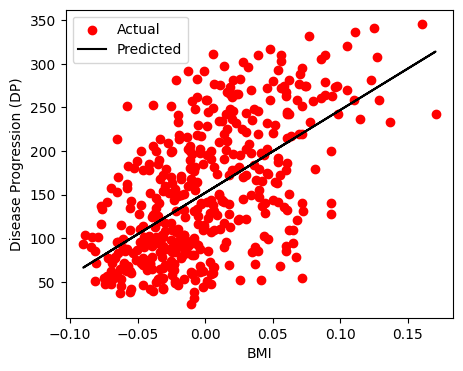

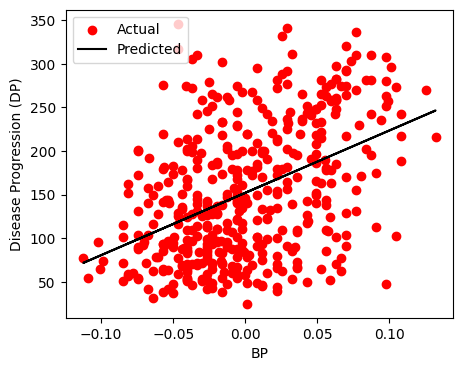

In [303]:
# Task 2 (continued)
def plot_closed_form(X, W, Y, feature_name):
    X_design = np.column_stack((np.ones(len(X)), X))
    y_vals = predict_dp(X_design, W)
    plt.figure(figsize=(5, 4))
    plt.scatter(X, Y, color='red', label='Actual')
    plt.plot(X, y_vals, color='black', label='Predicted')
    plt.xlabel(feature_name)
    plt.ylabel('Disease Progression (DP)')
    plt.legend(loc='upper left')
    plt.show()

plot_closed_form(X_bmi, W_bmi_cf, Y, "BMI")
plot_closed_form(X_bp, W_bp_cf, Y, "BP")


In [304]:
# Task 2 (continued)
results_table = pd.DataFrame({
    "Method": ["Gradient Descent", "Gradient Descent", "Closed-form", "Closed-form"],
    "Feature": ["BMI", "BP", "BMI", "BP"],
    "W0 (intercept)": [W_bmi_gd[0], W_bp_gd[0], W_bmi_cf[0], W_bp_cf[0]],
    "W1 (slope)": [W_bmi_gd[1], W_bp_gd[1], W_bmi_cf[1], W_bp_cf[1]],
    "MSE": [mse_bmi_gd, mse_bp_gd, mse_bmi_cf, mse_bp_cf]
})
results_table

,Method,Feature,W0 (intercept),W1 (slope),MSE
0,Gradient Descent,BMI,152.133484,949.435259,3890.456585
1,Gradient Descent,BP,152.133484,714.738258,4774.113902
2,Closed-form,BMI,152.133484,949.435260,3890.456585
3,Closed-form,BP,152.133484,714.738259,4774.113902


In [305]:
# Task 3
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X_bmi_sk = diabetes_data[["bmi"]]
reg_bmi = LinearRegression()
reg_bmi.fit(X_bmi_sk, Y)
pred_bmi_sk = reg_bmi.predict(X_bmi_sk)
mse_bmi_sk = mean_squared_error(Y, pred_bmi_sk)

print(f"[BMI, sklearn] Intercept = {reg_bmi.intercept_}, Coef = {reg_bmi.coef_}, MSE = {mse_bmi_sk}")


[BMI, sklearn] Intercept = 152.13348416289617, Coef = [949.43526038], MSE = 3890.456585461273


In [306]:
# Task 3 (continued)
X_bp_sk = diabetes_data[["bp"]]
reg_bp = LinearRegression()
reg_bp.fit(X_bp_sk, Y)
pred_bp_sk = reg_bp.predict(X_bp_sk)
mse_bp_sk = mean_squared_error(Y, pred_bp_sk)

print(f"[BP, sklearn] Intercept = {reg_bp.intercept_}, Coef = {reg_bp.coef_}, MSE = {mse_bp_sk}")

[BP, sklearn] Intercept = 152.13348416289597, Coef = [714.7382595], MSE = 4774.113902368687


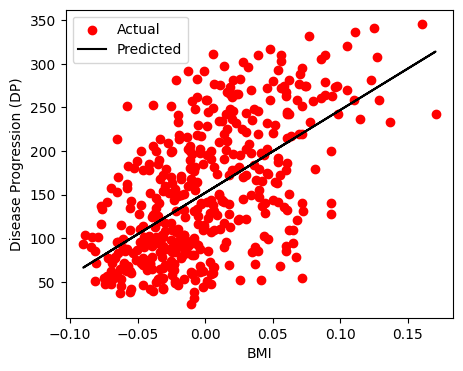

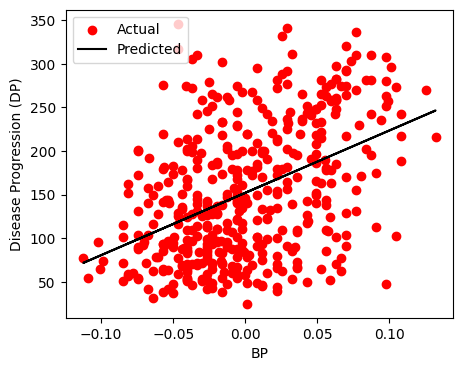

In [307]:
# Task 3 (continued)
plt.figure(figsize=(5, 4))
plt.scatter(X_bmi_sk, Y, color='red', label='Actual')
plt.plot(X_bmi_sk, pred_bmi_sk, color='black', label='Predicted')
plt.xlabel('BMI')
plt.ylabel('Disease Progression (DP)')
plt.legend(loc='upper left')
plt.show()

plt.figure(figsize=(5, 4))
plt.scatter(X_bp_sk, Y, color='red', label='Actual')
plt.plot(X_bp_sk, pred_bp_sk, color='black', label='Predicted')
plt.xlabel('BP')
plt.ylabel('Disease Progression (DP)')
plt.legend(loc='upper left')
plt.show()

In [308]:
# Task 3 (continued)
results_table = pd.DataFrame({
    "Method": ["Gradient Descent", "Gradient Descent", "Closed-form", "Closed-form", "Scikit-learn", "Scikit-learn"],
    "Feature": ["BMI", "BP", "BMI", "BP", "BMI", "BP"],
    "W0 (intercept)": [W_bmi_gd[0], W_bp_gd[0], W_bmi_cf[0], W_bp_cf[0], reg_bmi.intercept_, reg_bp.intercept_],
    "W1 (slope)": [W_bmi_gd[1], W_bp_gd[1], W_bmi_cf[1], W_bp_cf[1], reg_bmi.coef_[0], reg_bp.coef_[0]],
    "MSE": [mse_bmi_gd, mse_bp_gd, mse_bmi_cf, mse_bp_cf, mse_bmi_sk, mse_bp_sk]
})
results_table

,Method,Feature,W0 (intercept),W1 (slope),MSE
0,Gradient Descent,BMI,152.133484,949.435259,3890.456585
1,Gradient Descent,BP,152.133484,714.738258,4774.113902
2,Closed-form,BMI,152.133484,949.435260,3890.456585
3,Closed-form,BP,152.133484,714.738259,4774.113902
4,Scikit-learn,BMI,152.133484,949.435260,3890.456585
5,Scikit-learn,BP,152.133484,714.738259,4774.113902


Feature ranking (most to least important):
['s1', 's5', 'bmi', 's2', 'bp', 'sex', 's4', 's3', 's6', 'age']


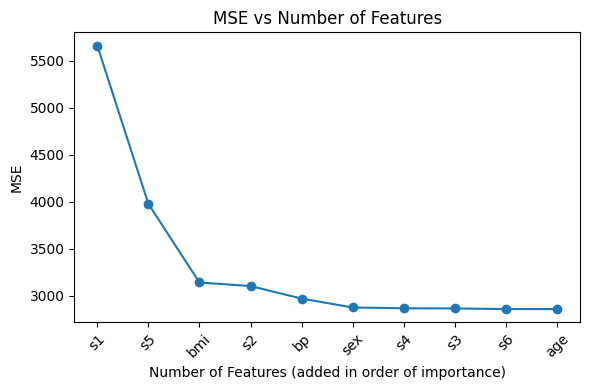

Using top 1 feature(s) (added: s1): MSE = 5663.32
Using top 2 feature(s) (added: s5): MSE = 3979.71
Using top 3 feature(s) (added: bmi): MSE = 3142.69
Using top 4 feature(s) (added: s2): MSE = 3104.44
Using top 5 feature(s) (added: bp): MSE = 2971.38
Using top 6 feature(s) (added: sex): MSE = 2876.68
Using top 7 feature(s) (added: s4): MSE = 2868.34
Using top 8 feature(s) (added: s3): MSE = 2866.67
Using top 9 feature(s) (added: s6): MSE = 2859.88
Using top 10 feature(s) (added: age): MSE = 2859.70


In [309]:
# Task 4
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X_all = diabetes_data[diabetes.feature_names]

reg_all = LinearRegression()
reg_all.fit(X_all, Y)

importance = pd.Series(np.abs(reg_all.coef_), index=diabetes.feature_names)
ranked_features = importance.sort_values(ascending=False).index.tolist()

print("Feature ranking (most to least important):")
print(ranked_features)
mse_list = []

for i in range(1, len(ranked_features) + 1):
    selected_features = ranked_features[:i]
    X_subset = diabetes_data[selected_features]

    reg = LinearRegression()
    reg.fit(X_subset, Y)
    pred = reg.predict(X_subset)
    mse = mean_squared_error(Y, pred)
    mse_list.append(mse)

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(ranked_features) + 1), mse_list, marker='o')
plt.xlabel('Number of Features (added in order of importance)')
plt.ylabel('MSE')
plt.title('MSE vs Number of Features')
plt.xticks(range(1, len(ranked_features) + 1), ranked_features, rotation=45)
plt.tight_layout()
plt.show()

for i, (f, m) in enumerate(zip(ranked_features, mse_list), 1):
    print(f"Using top {i} feature(s) (added: {f}): MSE = {m:.2f}")

I used all 10 features. Then I checked which features matter most.

The top 3 features are: s1, s5, and bmi.

When I add these 3 features, the error (MSE) goes down a lot.

After that, adding more features does not help much. The error only goes down a tiny bit.

So I think 3 or 4 features are enough. We do not need all 10 features.

In [310]:

# Task 5
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

X_all_values = X_all.values
Y_values = Y.values

k = 10
n_samples = len(X_all_values)
fold_size = n_samples // k

np.random.seed(42)
indices = np.random.permutation(n_samples)

mse_scores = []

for fold in range(k):
    start = fold * fold_size
    end = start + fold_size if fold != k - 1 else n_samples
    val_idx = indices[start:end]
    train_idx = np.concatenate([indices[:start], indices[end:]])

    X_train, X_val = X_all_values[train_idx], X_all_values[val_idx]
    Y_train, Y_val = Y_values[train_idx], Y_values[val_idx]

    reg = LinearRegression()
    reg.fit(X_train, Y_train)
    pred_val = reg.predict(X_val)

    mse_fold = mean_squared_error(Y_val, pred_val)
    mse_scores.append(mse_fold)
    print(f"Fold {fold+1}: MSE = {mse_fold:.2f}")

mean_mse = np.mean(mse_scores)
std_mse = np.std(mse_scores)

print(f"\nMean MSE across {k} folds: {mean_mse:.2f}")
print(f"Standard Deviation of MSE: {std_mse:.2f}")

Fold 1: MSE = 2668.93
Fold 2: MSE = 3158.09
Fold 3: MSE = 2458.24
Fold 4: MSE = 2902.70
Fold 5: MSE = 3547.46
Fold 6: MSE = 3028.33
Fold 7: MSE = 2235.74
Fold 8: MSE = 3095.20
Fold 9: MSE = 3761.21
Fold 10: MSE = 3431.35

Mean MSE across 10 folds: 3028.72
Standard Deviation of MSE: 457.00


In [311]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [312]:
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Copy of 02_ML_LR.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Copy of 02_ML_LR.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 20 image(s).
[NbConvertApp] Writing 1510337 bytes to /content/drive/MyDrive/Colab Notebooks/Copy of 02_ML_LR.html
